# Menschliche Validierung

Run All nach `python 05_analyze.py --prepare`. Quellen: `data/menschliche_faktenrelevanz.csv` und `data/human_qa/`. Abbildungen 5–7, 19/20; Tabellen 5/6. Die Kalibrierung verwendet dieselben Fälle und ist keine unabhängige Validierung.

In [1]:
from pathlib import Path
from fractions import Fraction
from collections import Counter
from itertools import combinations
import hashlib, importlib.metadata, json, math, platform, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from threadpoolctl import threadpool_limits
from faktenretention.io import PROJECT_ROOT
from faktenretention.data import load_inputs, panel, length_values, reconstruct_qa, aggregate_articles, CELL, KEY
from faktenretention.protocol import METHODS, STAGES, WINDOWS, CONTRASTS, LABELS
threadpool_limits(limits=1)
SEED, B, N_FACTS = (32, 10000, 20)
DATA_DIR = PROJECT_ROOT / 'data'
OUT = PROJECT_ROOT / 'results/01_menschliche_validierung'
FIG = OUT
OUT.mkdir(parents=True, exist_ok=True)
COLORS = dict(zip(METHODS, ['#777777', '#0072B2', '#E69F00', '#009E73', '#CC79A7', '#D55E00']))
MARKERS = dict(zip(METHODS, ['o', 's', '^', 'D', 'v', 'P']))
LINESTYLES = dict(zip(METHODS, ['--', '-', '-.', '--', ':', '-']))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 26)

def export(frame, name):
    frame.to_csv(OUT / f'{name}.csv', index=False)

def fmt(x, d=2):
    return f'{x:.{d}f}'.replace('.', ',')

def savefig(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## Faktenrelevanz und Auswahl der Top 20

In [2]:
human_validation = pd.read_csv(DATA_DIR / 'menschliche_faktenrelevanz.csv', encoding='utf-8-sig')

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score
from IPython.display import display, Markdown
from itertools import combinations
from collections import Counter
df = human_validation.copy()
reviewers = [f'bewertung_teilnehmer_{i}' for i in range(1, 6)]
labels = ['Peripheral', 'Supporting', 'Core']
colors = ['#a8afb8', '#e4ad42', '#286a9f']
articles = sorted(df.artikel_id.unique())
assert len(df) == 168 and df.fakt_id.is_unique and (not df.isna().any().any())
assert df[reviewers + ['median', 'bewertung_modell']].isin([0, 1, 2]).all().all()
assert df[reviewers].median(axis=1).eq(df['median']).all()
assert df.in_top_20_laut_modell.eq(df.rang_laut_modell.le(20)).all()
assert df.groupby('artikel_id').in_top_20_laut_modell.sum().eq(20).all()
FIG_DIR = OUT
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 130, 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'savefig.facecolor': 'white'})

def save_figure(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [4]:
def ordinal_alpha(ratings):
    """Ordinales Krippendorff-Alpha; vollständige, gleich große Ratergruppen."""
    counts = Counter(ratings.ravel().tolist())

    def distance(a, b):
        if a == b:
            return 0.0
        lo, hi = sorted((a, b))
        return (sum((counts[c] for c in range(lo, hi + 1))) - (counts[lo] + counts[hi]) / 2) ** 2
    observed = np.mean([distance(a, b) for unit in ratings for i, a in enumerate(unit) for j, b in enumerate(unit) if i != j])
    n = ratings.size
    expected = sum((counts[a] * counts[b] * distance(a, b) for a in counts for b in counts)) / (n * (n - 1))
    return 1 - observed / expected

def ndcg(values):
    values = np.asarray(values)
    discounts = np.log2(np.arange(2, min(20, len(values)) + 2))
    gains = values
    ideal = np.sort(gains)[::-1][:20]
    return (gains[:20] / discounts).sum() / (ideal / discounts).sum()
article_rows = []
for article, group in df.groupby('artikel_id'):
    ranked = group.sort_values('rang_laut_modell')
    top = ranked[ranked.in_top_20_laut_modell]
    core_total = group['median'].eq(2).sum()
    article_rows.append({'Artikel': article, 'Kandidaten': len(group), 'Core gesamt': core_total, 'Core in Top 20': top['median'].eq(2).sum(), 'Precision@20': top['median'].ge(1).mean(), 'Core-Recall@20': top['median'].eq(2).sum() / core_total, 'nDCG@20 (linear 0/1/2)': ndcg(ranked['median']), 'Spearman Rang–Median': ranked[['rang_laut_modell', 'median']].corr(method='spearman').iloc[0, 1]})
article_metrics = pd.DataFrame(article_rows).set_index('Artikel')
top20 = df[df.in_top_20_laut_modell]
alpha = ordinal_alpha(df[reviewers].to_numpy())
accuracy = accuracy_score(df['median'], df.bewertung_modell)
kappa = cohen_kappa_score(df['median'], df.bewertung_modell, weights='linear')
unanimous = df[reviewers].nunique(axis=1).eq(1).sum()
summary = pd.Series({'Fakten': len(df), 'Artikel': len(articles), 'Einzelurteile': df[reviewers].size, 'Precision@20 (gepoolt)': top20['median'].ge(1).mean(), 'Core-Recall@20 (gepoolt)': top20['median'].eq(2).sum() / df['median'].eq(2).sum(), 'Core-Recall@20 (Artikelmittel)': article_metrics['Core-Recall@20'].mean(), 'nDCG@20 (linear, Artikelmittel)': article_metrics['nDCG@20 (linear 0/1/2)'].mean(), 'Modell–Mensch: exakte Übereinstimmung': accuracy, 'Modell–Mensch: linear gewichtetes Kappa': kappa, 'Ordinales Krippendorff-Alpha': alpha, 'Vollständig übereinstimmende Fakten': unanimous}, name='Wert')
display(summary.to_frame().round(4))
display(article_metrics.round(4))
summary.to_csv(FIG_DIR / 'kennzahlen.csv')
article_metrics.to_csv(FIG_DIR / 'kennzahlen_je_artikel.csv')
assert np.isclose(alpha, 0.458867, atol=1e-06)
assert np.isclose(kappa, 0.542044, atol=1e-06)

,Wert
Fakten,168.0000
Artikel,5.0000
Einzelurteile,840.0000
Precision@20 (gepoolt),0.8800
Core-Recall@20 (gepoolt),0.9429
Core-Recall@20 (Artikelmittel),0.9381
"nDCG@20 (linear, Artikelmittel)",0.9141
Modell–Mensch: exakte Übereinstimmung,0.6667
Modell–Mensch: linear gewichtetes Kappa,0.5420
Ordinales Krippendorff-Alpha,0.4589


,Kandidaten,Core gesamt,Core in Top 20,Precision@20,Core-Recall@20,nDCG@20 (linear 0/1/2),Spearman Rang–Median
Artikel,,,,,,,
cnndm-train-055917,32,7,7,0.80,1.0000,0.9377,-0.8038
cnndm-train-070473,34,6,6,0.95,1.0000,0.9329,-0.6359
cnndm-train-137777,34,6,5,1.00,0.8333,0.9390,-0.8415
cnndm-train-141898,34,9,9,0.65,1.0000,0.8159,-0.5219
cnndm-train-196250,34,7,6,1.00,0.8571,0.9452,-0.6759


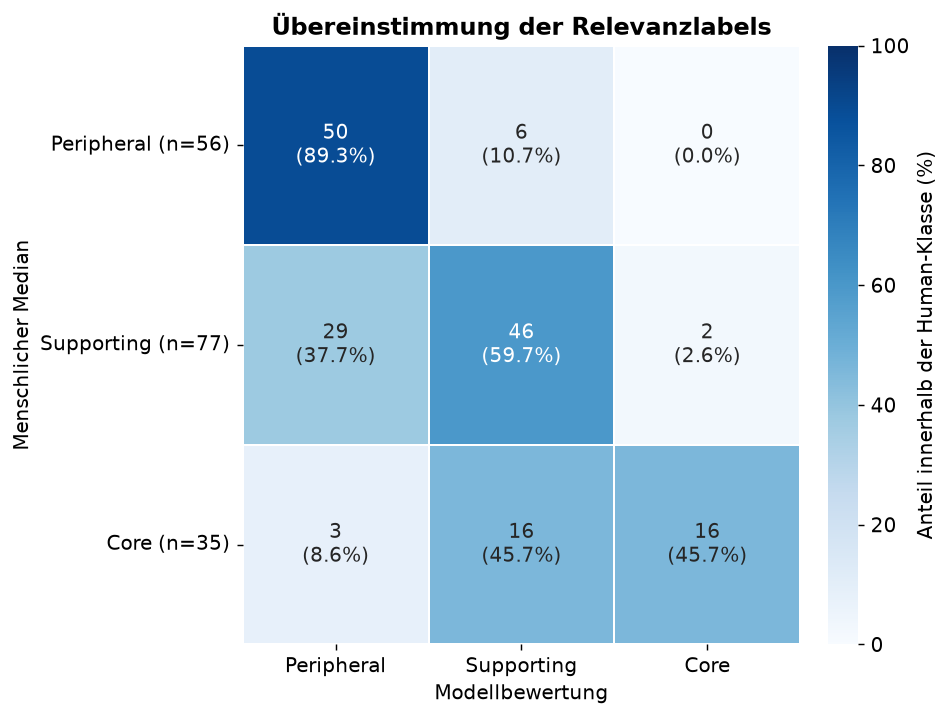

In [5]:
confusion = pd.crosstab(df['median'], df.bewertung_modell).reindex(index=range(3), columns=range(3), fill_value=0)
row_pct = confusion.div(confusion.sum(axis=1), axis=0) * 100
annotations = np.array([[f'{confusion.iloc[i, j]}\n({row_pct.iloc[i, j]:.1f}%)' for j in range(3)] for i in range(3)])
fig, ax = plt.subplots(figsize=(7.2, 5.4), layout='constrained')
sns.heatmap(row_pct, annot=annotations, fmt='', cmap='Blues', vmin=0, vmax=100, xticklabels=labels, yticklabels=[f'{labels[i]} (n={confusion.sum(axis=1).iloc[i]})' for i in range(3)],
    linewidths=1, cbar_kws={'label': 'Anteil innerhalb der Human-Klasse (%)'}, ax=ax)
ax.set(xlabel='Modellbewertung', ylabel='Menschlicher Median', title='Übereinstimmung der Relevanzlabels')
ax.tick_params(axis='y', rotation=0)
save_figure(fig, 'abb_05_relevanzkonfusion')

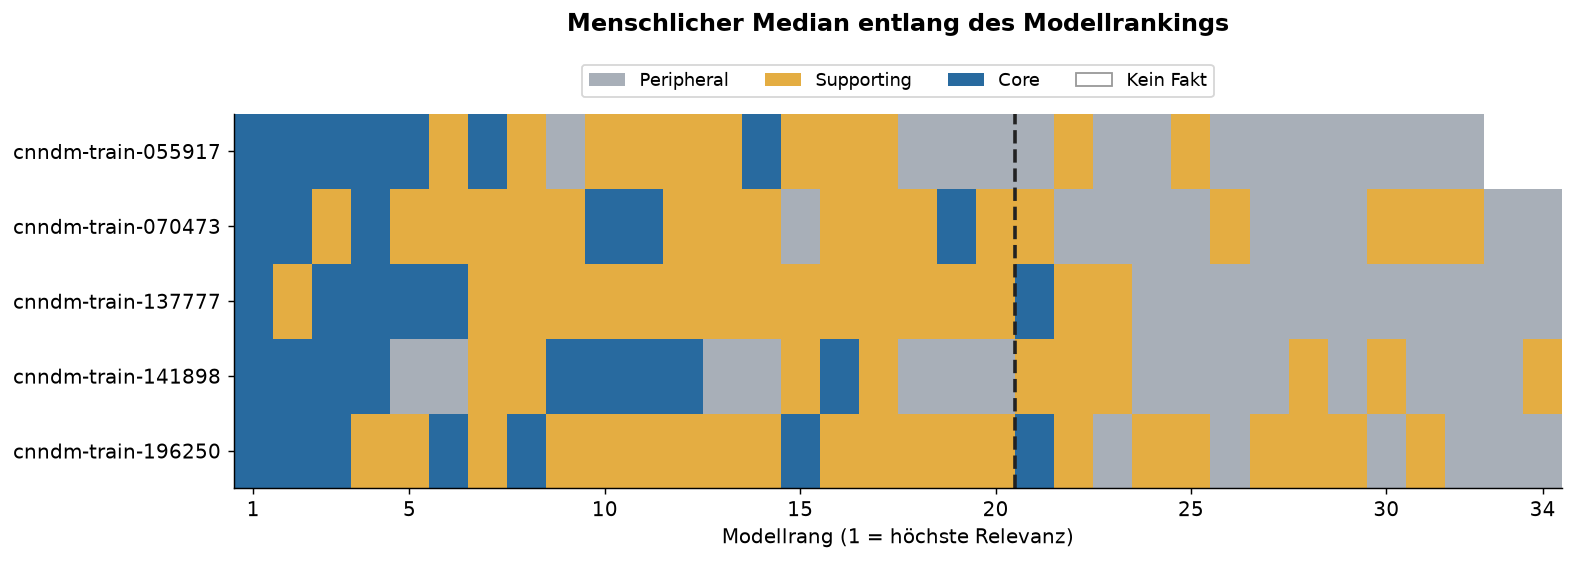

In [6]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
rank_matrix = df.pivot(index='artikel_id', columns='rang_laut_modell', values='median').reindex(index=articles,
    columns=range(1, 35))
fig, ax = plt.subplots(figsize=(12, 4.2), layout='constrained')
cmap = ListedColormap(colors)
cmap.set_bad('white')
ax.imshow(rank_matrix.to_numpy(), aspect='auto', cmap=cmap, norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3))
ax.axvline(19.5, color='#222222', linewidth=2, linestyle='--')
ax.set(yticks=range(5), yticklabels=articles, xticks=[0, 4, 9, 14, 19, 24, 29, 33], xticklabels=[1, 5,
    10, 15, 20, 25, 30, 34], xlabel='Modellrang (1 = höchste Relevanz)', title='Menschlicher Median entlang des Modellrankings')
ax.legend(handles=[Patch(facecolor=colors[i], label=labels[i]) for i in range(3)] + [Patch(facecolor='white',
    edgecolor='#999999', label='Kein Fakt')], ncols=4, loc='lower center', bbox_to_anchor=(0.5, 1.02), fontsize=10)
ax.set_title(ax.get_title(),pad=46)
save_figure(fig, 'abb_06_relevanzranking')

## Quellenbeleg, Atomarität und Tabelle 5

Die Originalrückgaben enthalten zusätzlich Quellenstützung, Atomarität und Artikelerweiterungen. Der Kalibrierungsartikel wird über die fünf formalen Artikel der Relevanztabelle ausgeschlossen; Relevanzratings werden positionsgenau abgeglichen.

In [7]:
import zipfile, io
with zipfile.ZipFile(DATA_DIR / 'menschliche_relevanz_quellen.zip') as archive:
    original_ratings = pd.concat([pd.read_csv(io.BytesIO(archive.read(f'reviewer_{i:02d}_facts.csv')),
        keep_default_na=False) for i in range(1, 6)], ignore_index=True)
    candidate_pool = pd.read_json(io.BytesIO(archive.read('candidate_pool.jsonl')), lines=True)
    validation_articles = pd.read_csv(io.BytesIO(archive.read('selected_articles.csv')), keep_default_na=False)
formal = original_ratings[original_ratings.article_id.isin(df.artikel_id.unique())].copy()
assert len(formal) == 840
for i in range(1, 6):
    values = formal[formal.reviewer_id.eq(f'reviewer_{i:02d}')].set_index('fact_id').human_relevance_value
    assert (df.fakt_id.map(values) - 1).eq(df[f'bewertung_teilnehmer_{i}']).all()
quality_rows = []
for field in ['source_supported', 'atomicity']:
    for value, count in formal[field].value_counts().items():
        quality_rows.append(dict(dimension=field, value=value, count=int(count), denominator=len(formal),
            proportion=count / len(formal)))
quality = pd.DataFrame(quality_rows)
export(quality, 'relevanz_quellenstuetzung_atomaritaet')
table5 = pd.crosstab(top20.artikel_id, top20['median']).reindex(index=articles, columns=[2, 1, 0], fill_value=0).rename(columns={2: 'Core',
    1: 'Supporting', 0: 'Peripheral'})
export(table5.reset_index(), 'tabelle_5_top20_relevanz')
display(quality)
display(table5)

,dimension,value,count,denominator,proportion
0,source_supported,Yes,837,840,0.996429
1,source_supported,No,3,840,0.003571
2,atomicity,Atomic,840,840,1.000000


median,Core,Supporting,Peripheral
artikel_id,,,
cnndm-train-055917,7,9,4
cnndm-train-070473,6,13,1
cnndm-train-137777,5,15,0
cnndm-train-141898,9,4,7
cnndm-train-196250,6,14,0


## Relevanzurteile je Person und paarweise Übereinstimmung

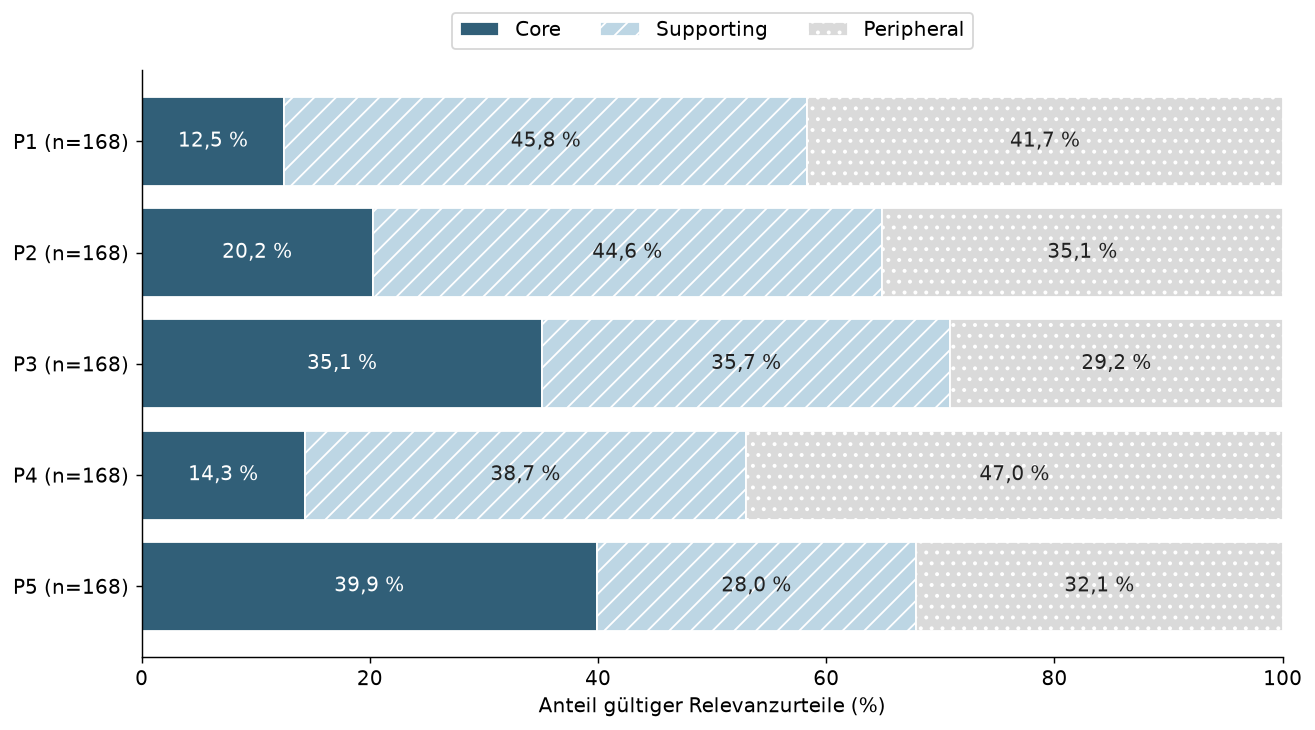

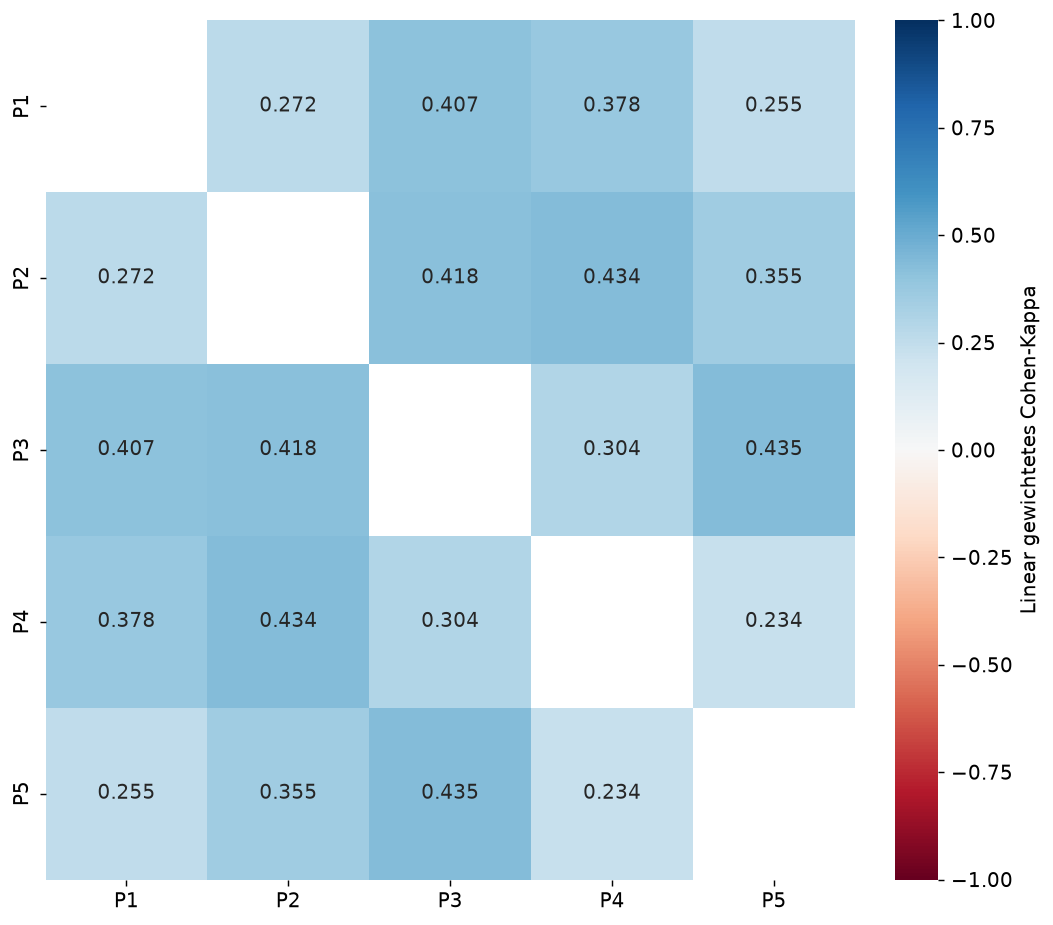

In [8]:
reviewer_counts = pd.DataFrame({r: df[r].value_counts().reindex(range(3), fill_value=0) for r in reviewers}).T
export(reviewer_counts.reset_index(), 'relevanzurteile_je_person')
fig, ax = plt.subplots(figsize=(10, 5.5), layout='constrained')
left = np.zeros(5)
for category, color, hatch in [(2, '#315f78', ''), (1, '#bdd6e4', '//'), (0, '#dadada', '..')]:
    values = 100 * reviewer_counts[category].to_numpy() / 168
    ax.barh(range(5), values, left=left, color=color, hatch=hatch, edgecolor='white', label=labels[category])
    for i, v in enumerate(values):
        ax.text(left[i] + v / 2, i, fmt(v, 1) + ' %', ha='center', va='center', color='white' if category == 2 else '#222222')
    left += values
ax.set(yticks=range(5), yticklabels=[f'P{i} (n=168)' for i in range(1, 6)], xlim=(0, 100), xlabel='Anteil gültiger Relevanzurteile (%)')
ax.invert_yaxis()
ax.legend(ncols=3, loc='lower center', bbox_to_anchor=(0.5, 1.02))
savefig(fig, 'abb_19_relevanzurteile')
kappas = np.full((5, 5), np.nan)
for i, j in combinations(range(5), 2):
    kappas[i, j] = kappas[j, i] = cohen_kappa_score(df[reviewers[i]], df[reviewers[j]], weights='linear')
export(pd.DataFrame(kappas, index=reviewers, columns=reviewers).reset_index(), 'relevanz_kappa_paare')
fig, ax = plt.subplots(figsize=(8, 7), layout='constrained')
sns.heatmap(kappas, mask=np.eye(5, dtype=bool), annot=True, fmt='.3f', cmap='RdBu', vmin=-1, vmax=1, ax=ax,
    xticklabels=[f'P{i}' for i in range(1, 6)], yticklabels=[f'P{i}' for i in range(1, 6)], cbar_kws={'label': 'Linear gewichtetes Cohen-Kappa'})
savefig(fig, 'abb_20_relevanzkappa')

## QA-Fallauswahl und menschliche Referenz

60 deterministisch quotierte Fälle, sieben Rückgaben. Eindeutiger Drei-Klassen-Konsens: 52 Fälle; historische Auflösung von Gleichständen: 58. Die Bewertungsmasken und die Auswahlregel bleiben in `data/` erhalten.

In [9]:
from pathlib import Path
from collections import Counter
from itertools import combinations
import hashlib, importlib.util, json, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, confusion_matrix, precision_recall_fscore_support
from IPython.display import display, Markdown
BASE = DATA_DIR
DATA = DATA_DIR / 'human_qa'
OUT.mkdir(exist_ok=True)
LABELS = ['retained', 'lost', 'unsupported']
QUESTION_LABELS = ['good', 'partial', 'bad', 'unclear']
ANSWER_LABELS = LABELS + ['unclear']
COLORS = {'retained': '#286a9f', 'lost': '#a8afb8', 'unsupported': '#c27c2c', 'unclear': '#75658f'}
plt.rcParams.update({'figure.dpi': 130, 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'savefig.facecolor': 'white'})
pd.set_option('display.max_colwidth', 85)
pd.set_option('display.max_rows', 24)

def read(relative):
    return pd.read_csv(DATA / relative, keep_default_na=False)

def export(table, name):
    table.to_csv(OUT / f'{name}.csv', index=False)

def savefig(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def bool_col(series):
    return series.astype(str).str.lower().isin(['true', '1'])

def pct(value):
    return f'{value * 100:.1f} %'.replace('.', ',')

In [10]:
key = read('internal_model_label_key.csv')
assert len(key) == 60 and key.review_id.is_unique
assert key[['article_id', 'method', 'stage_target_words', 'canonical_fact_id']].duplicated().sum() == 0
returns = []
audit_rows = []
for path in sorted((DATA / 'returns').glob('reviewer_*_answers.csv')):
    frame = pd.read_csv(path, keep_default_na=False)
    assert len(frame) == 60 and frame.review_id.is_unique
    assert set(frame.review_id) == set(key.review_id)
    frame['reviewer_id'] = path.stem.removesuffix('_answers')
    for field, allowed in [('question_quality', QUESTION_LABELS), ('human_answer_label', ANSWER_LABELS)]:
        normalized = frame[field].astype(str).str.strip().str.lower().str.replace(' ', '_', regex=False).str.replace('-', '_', regex=False)
        audit_rows.append({'Reviewer': frame.reviewer_id.iloc[0], 'Feld': field, 'Leer': normalized.eq('').sum(),
            'Ungültig': (~normalized.isin(allowed + [''])).sum()})
        frame[field] = normalized.where(normalized.isin(allowed), pd.NA)
    returns.append(frame[['review_id', 'reviewer_id', 'question_quality', 'human_answer_label', 'overall_notes']])
annotations = pd.concat(returns, ignore_index=True).merge(key.drop(columns=['question_quality', 'human_answer_label',
    'overall_notes']), on='review_id', validate='many_to_one')
annotations['complete'] = annotations[['question_quality', 'human_answer_label']].notna().all(axis=1)
audit = pd.DataFrame(audit_rows)
assert len(annotations) == 420 and annotations.complete.sum() == 204
assert audit['Ungültig'].sum() == 0
assert key.article_id.nunique() == 6 and key.canonical_fact_id.nunique() == 25
assert key.model_label.value_counts().eq(20).all()
assert key.method.value_counts().eq(20).all()
assert key.stage_target_words.value_counts().eq(15).all()
display(pd.DataFrame({'Dimension': ['QA-Fälle', 'Artikel', 'Einzigartige Fakten/Fragen', 'Reviewer', 'Mögliche Urteilszeilen',
    'Vollständige Urteilszeilen'], 'Anzahl': [len(key), key.article_id.nunique(), key.canonical_fact_id.nunique(),
    len(returns), len(annotations), annotations.complete.sum()]}))

,Dimension,Anzahl
0,QA-Fälle,60
1,Artikel,6
2,Einzigartige Fakten/Fragen,25
3,Reviewer,7
4,Mögliche Urteilszeilen,420
5,Vollständige Urteilszeilen,204


### Deterministische Auswahl aus den ursprünglichen 2.400 QA-Positionen

Die ursprüngliche Greedy-Auswahl priorisiert Labelquoten (Gewicht 100), Stufen- und Methodenquoten (je 25) und danach Artikel-/Entitätsabdeckung. Die unveränderte Auswahlregel reproduziert die 60 ausgelieferten Fälle in derselben Reihenfolge.

In [11]:
from collections import defaultdict
qa_rows=pd.read_csv(DATA/'auswahlkandidaten.csv.gz',keep_default_na=False,dtype=str).to_dict('records')
def select_historical_cases(qa_rows):
    def model_label(row: dict[str, str]) -> str:
        if row.get('retention') == 'True':
            return 'retained'
        if row.get('loss') == 'True':
            return 'lost'
        if row.get('unsupported_or_hallucinated') == 'True':
            return 'unsupported'
        return 'unclear'
    preferred_articles = {'1', '2', '3', '4', '5', '6'}
    preferred_prompts = {'plain', 'few_shot_cot', 'zero_shot_cot'}
    preferred_stages = {'500', '300', '150', '75'}
    candidates = [row for row in qa_rows if row['article_id'] in preferred_articles and row['summary_prompt_variant'] in preferred_prompts and (row['stage_target_words'] in preferred_stages)]
    targets = {'model_label': {'retained': 20, 'lost': 20, 'unsupported': 20}, 'stage_target_words': {'500': 15,
        '300': 15, '150': 15, '75': 15}, 'summary_prompt_variant': {'plain': 20, 'few_shot_cot': 20, 'zero_shot_cot': 20}}
    selected: list[dict[str, str]] = []
    used_keys: set[tuple[str, str, str, str]] = set()
    counts: dict[tuple[str, str], int] = defaultdict(int)
    
    def deficit(category: str, value: str) -> int:
        return max(targets[category].get(value, 0) - counts[category, value], 0)
    
    def row_score(row: dict[str, str]) -> tuple[int, int, int, str]:
        label = model_label(row)
        stage = row['stage_target_words']
        prompt = row['summary_prompt_variant']
        entity = row['entity_type']
        article = row['article_id']
        return (deficit('model_label', label) * 100 + deficit('stage_target_words', stage) * 25 + deficit('summary_prompt_variant',
            prompt) * 25 + max(8 - counts['article_id', article], 0) * 4 + max(6 - counts['entity_type',
            entity], 0), -counts['article_id', article], -counts['entity_type', entity], row['canonical_fact_id'])
    while len(selected) < 60:
        eligible = []
        for row in candidates:
            label = model_label(row)
            stage = row['stage_target_words']
            prompt = row['summary_prompt_variant']
            key = (prompt, row['article_id'], stage, row['canonical_fact_id'])
            if key in used_keys:
                continue
            if counts['model_label', label] >= targets['model_label'][label]:
                continue
            if counts['stage_target_words', stage] >= targets['stage_target_words'][stage]:
                continue
            if counts['summary_prompt_variant', prompt] >= targets['summary_prompt_variant'][prompt]:
                continue
            eligible.append(row)
        if not eligible:
            break
        row = max(eligible, key=row_score)
        key = (row['summary_prompt_variant'], row['article_id'], row['stage_target_words'], row['canonical_fact_id'])
        selected.append(row)
        used_keys.add(key)
        counts['model_label', model_label(row)] += 1
        counts['stage_target_words', row['stage_target_words']] += 1
        counts['summary_prompt_variant', row['summary_prompt_variant']] += 1
        counts['article_id', row['article_id']] += 1
        counts['entity_type', row['entity_type']] += 1
    selected = sorted(selected, key=lambda r: (int(r['article_id']), int(r['stage_target_words']), r['summary_prompt_variant'],
        r['canonical_fact_id']))
    return selected
selected=select_historical_cases(qa_rows)
actual=[(int(r['article_id']),r['summary_prompt_variant'],int(r['stage_target_words']),r['canonical_fact_id']) for r in selected]
expected=list(key[['article_id','method','stage_target_words','canonical_fact_id']].itertuples(index=False,name=None))
assert actual==expected and len(actual)==60
print('Die deterministische Fallauswahl reproduziert HV001–HV060 positionsgenau.')

Die deterministische Fallauswahl reproduziert HV001–HV060 positionsgenau.


In [12]:
sample_rows = []
for dimension in ['article_id', 'method', 'stage_target_words', 'entity_type', 'model_label']:
    for value, count in key[dimension].value_counts().sort_index().items():
        sample_rows.append({'Dimension': dimension, 'Ausprägung': str(value), 'Fälle': count})
sample = pd.DataFrame(sample_rows)
display(sample)
display(pd.crosstab(key.method, key.stage_target_words))
export(sample, 'stichprobenzusammensetzung')

,Dimension,Ausprägung,Fälle
0,article_id,1,10
1,article_id,2,10
2,article_id,3,10
3,article_id,4,10
4,article_id,5,10
5,article_id,6,10
6,method,few_shot_cot,20
7,method,plain,20
8,method,zero_shot_cot,20
9,stage_target_words,75,15


stage_target_words,75,150,300,500
method,,,,
few_shot_cot,4,5,6,5
plain,6,6,3,5
zero_shot_cot,5,4,6,5


In [13]:
completion = annotations.groupby('reviewer_id').agg(erwartete_faelle=('review_id', 'size'), vollstaendig=('complete',
    'sum'), fragenurteile=('question_quality', 'count'), antworturteile=('human_answer_label', 'count')).reset_index()
completion['anteil_vollstaendig'] = completion.vollstaendig / completion.erwartete_faelle
assert completion.vollstaendig.tolist() == [60, 2, 30, 7, 6, 39, 60]
valid_answer = annotations[annotations.human_answer_label.notna()]
valid_question = annotations[annotations.question_quality.notna()]
per_item_votes = valid_answer.groupby('review_id').size()
display(per_item_votes.value_counts().sort_index().rename_axis('Gültige Stimmen pro Fall').rename('Anzahl Fälle').to_frame())

,Anzahl Fälle
Gültige Stimmen pro Fall,
2,6
3,30
4,18
5,6


In [14]:
def consensus_table(frame, field):
    records = []
    for review_id, group in frame.groupby('review_id', sort=True):
        labels = group[field].dropna().tolist()
        counts = Counter(labels)
        if not counts:
            records.append({'review_id': review_id, 'label': pd.NA, 'tie': False, 'votes': 0, 'max_votes': 0,
                'strict_majority': False, 'unanimous': False})
            continue
        max_votes = max(counts.values())
        winners = sorted((k for k, v in counts.items() if v == max_votes))
        records.append({'review_id': review_id, 'label': winners[0], 'tie': len(winners) > 1, 'votes': len(labels),
            'max_votes': max_votes, 'strict_majority': max_votes > len(labels) / 2, 'unanimous': len(counts) == 1})
    return pd.DataFrame(records)
answer_consensus = consensus_table(annotations, 'human_answer_label')
question_consensus = consensus_table(annotations, 'question_quality')
items = key.merge(answer_consensus.rename(columns={'label': 'human_label'}), on='review_id', validate='one_to_one')
items = items.merge(question_consensus[['review_id', 'label', 'tie']].rename(columns={'label': 'human_question_quality',
    'tie': 'question_tie'}), on='review_id', validate='one_to_one')
items['legacy_eligible'] = items.human_label.isin(LABELS)
items['strict_eligible'] = items.legacy_eligible & ~items.tie
assert items.legacy_eligible.sum() == 58 and items.strict_eligible.sum() == 52
assert items.tie.sum() == 6 and items.question_tie.sum() == 2
qcounts = valid_question.question_quality.value_counts().reindex(QUESTION_LABELS, fill_value=0)
assert qcounts.tolist() == [172, 19, 6, 7]
quality = qcounts.rename_axis('Label').rename('Urteile').reset_index()
quality['Anteil'] = quality.Urteile / len(valid_question)
display(quality.round(4))
export(quality, 'fragenqualitaet')

,Label,Urteile,Anteil
0,good,172,0.8431
1,partial,19,0.0931
2,bad,6,0.0294
3,unclear,7,0.0343


In [15]:
def nominal_alpha(frame, field, allowed):
    coincidence = np.zeros((len(allowed), len(allowed)), dtype=float)
    usable_units = 0
    for _, group in frame.groupby('review_id'):
        values = group.loc[group[field].isin(allowed), field]
        m = len(values)
        if m < 2:
            continue
        count = values.value_counts().reindex(allowed, fill_value=0).to_numpy(dtype=float)
        coincidence += (np.outer(count, count) - np.diag(count)) / (m - 1)
        usable_units += 1
    n = coincidence.sum()
    if n < 2:
        return (np.nan, usable_units)
    marginal = coincidence.sum(axis=0)
    observed = (n - np.trace(coincidence)) / n
    expected = (n * n - np.sum(marginal * marginal)) / (n * (n - 1))
    return (1 - observed / expected if expected else np.nan, usable_units)
example = pd.DataFrame({'review_id': list(range(12)) * 2, 'x': list('aabb dcccedda'.replace(' ', '')) + list('babbbccceddd')})
example_alpha, _ = nominal_alpha(example, 'x', list('abcde'))
assert np.isclose(example_alpha, 0.6919642857142857), example_alpha
reliability_rows = []
for field, allowed in [('question_quality', QUESTION_LABELS), ('human_answer_label', ANSWER_LABELS)]:
    matches = total = 0
    unit_agreement = []
    for _, group in annotations.groupby('review_id'):
        pairs = list(combinations(group[field].dropna(), 2))
        if pairs:
            unit_matches = sum((a == b for a, b in pairs))
            matches += unit_matches
            total += len(pairs)
            unit_agreement.append(unit_matches / len(pairs))
    alpha, usable = nominal_alpha(annotations, field, allowed)
    reliability_rows.append({'Dimension': field, 'Übereinstimmende Paare': matches, 'Gültige Paare': total,
        'Rohe Paarübereinstimmung': matches / total, 'Fallmittel der Paarübereinstimmung': np.mean(unit_agreement),
        'Nominales Alpha': alpha, 'Fälle für Alpha': usable})
reliability = pd.DataFrame(reliability_rows)
assert reliability['Übereinstimmende Paare'].tolist() == [184, 149]
assert reliability['Gültige Paare'].tolist() == [264, 264]
answer_alpha, _ = nominal_alpha(annotations, 'human_answer_label', ANSWER_LABELS)
answer_alpha_three, alpha_three_n = nominal_alpha(annotations, 'human_answer_label', LABELS)
display(reliability.round(4))
export(reliability, 'reliabilitaet')

,Dimension,Übereinstimmende Paare,Gültige Paare,Rohe Paarübereinstimmung,Fallmittel der Paarübereinstimmung,Nominales Alpha,Fälle für Alpha
0,question_quality,184,264,0.6970,0.7267,-0.0337,60
1,human_answer_label,149,264,0.5644,0.5578,0.2967,60


In [16]:
comparable_rows = annotations[annotations.human_answer_label.isin(LABELS)].copy()
row_matches = comparable_rows.model_label.eq(comparable_rows.human_answer_label).sum()
assert len(comparable_rows) == 182 and row_matches == 106

def metric_row(frame, prediction, name):
    y = frame.human_label
    p = frame[prediction]
    if not len(frame):
        return {'Auswertung': name, 'Fälle': 0, 'Übereinstimmungen': 0, 'Accuracy': np.nan, 'Kappa': np.nan,
            'Macro-F1': np.nan}
    return {'Auswertung': name, 'Fälle': len(frame), 'Übereinstimmungen': int(y.eq(p).sum()), 'Accuracy': accuracy_score(y,
        p), 'Kappa': cohen_kappa_score(y, p, labels=LABELS), 'Macro-F1': f1_score(y, p, labels=LABELS,
        average='macro', zero_division=0)}
baseline = pd.DataFrame([metric_row(items[items.legacy_eligible], 'model_label', 'Historisch: unclear ausgeschlossen, Ties alphabetisch'),
    metric_row(items[items.strict_eligible], 'model_label', 'Primär: eindeutiges Drei-Klassen-Label')])
display(baseline.round(4))
assert baseline['Übereinstimmungen'].tolist() == [33, 32]
strict = items[items.strict_eligible].copy()
majority_class = strict.human_label.mode().iloc[0]
majority_baseline = strict.human_label.eq(majority_class).mean()

,Auswertung,Fälle,Übereinstimmungen,Accuracy,Kappa,Macro-F1
0,"Historisch: unclear ausgeschlossen, Ties alphabetisch",58,33,0.5690,0.3521,0.4709
1,Primär: eindeutiges Drei-Klassen-Label,52,32,0.6154,0.4174,0.5077


## Kalibrierung und QA-Konfusion

Die Antworttexte bleiben unverändert. Historisches `unsupported` ist keine unabhängig bestätigte Halluzinationsmessung.

In [17]:
from faktenretention import scoring as scorer

def original_retained(reference, answer):
    if answer.upper() == 'NOT_FOUND':
        return False
    r, a = (scorer.normalize(reference), scorer.normalize(answer))
    return bool(r and (r in a or a in r)) or scorer.token_f1(reference, answer) >= 0.5

def first_patch_canonical(text):
    text = scorer.normalize(text)
    for source, target in [('u s a', 'united states'), ('u s', 'united states'), ('usa', 'united states'),
        ('us', 'united states')]:
        text = re.sub(f'\\b{source}\\b', target, text)
    decades = {'one': 10, 'two': 20, 'three': 30, 'four': 40, 'five': 50, 'six': 60, 'seven': 70, 'eight': 80,
        'nine': 90, 'ten': 100}
    for word, years in decades.items():
        text = re.sub(f'\\bover {word} decades?\\b', f'more than {years} years', text)
        text = re.sub(f'\\b{word} decades?\\b', f'{years} years', text)
    return text

def first_patch_retained(reference, answer):
    if original_retained(reference, answer):
        return True
    if answer.upper() == 'NOT_FOUND':
        return False
    r, a = (first_patch_canonical(reference), first_patch_canonical(answer))
    if r and (r in a or a in r):
        return True
    return bool(0 < len(r.split()) <= 10 and len(a.split()) / len(r.split()) <= 4 and (scorer.token_f1(r, a) >= 0.43))

def classify(reference, answer, retained_function):
    return 'lost' if answer.upper() == 'NOT_FOUND' else 'retained' if retained_function(reference, answer) else 'unsupported'
items['reconstructed_original'] = [classify(r, a, original_retained) for r, a in zip(items.reference_answer,
    items.model_answer)]
assert items.reconstructed_original.eq(items.model_label).all()
items['first_patch'] = [classify(r, a, first_patch_retained) for r, a in zip(items.reference_answer, items.model_answer)]
items['calibrated'] = [classify(r, a, scorer.retained) for r, a in zip(items.reference_answer, items.model_answer)]
versions = [('model_label', 'Ursprünglich'), ('first_patch', 'Erste Kalibrierung (rekonstruiert)'), ('calibrated',
    'Generalisierte Kalibrierung (Snapshot)')]
calibration_rows = []
for mask, name in [(items.legacy_eligible, 'Historisch (n=58)'), (items.strict_eligible, 'Eindeutig (n=52)')]:
    for column, title in versions:
        row = metric_row(items[mask], column, title)
        row['Vergleichsset'] = name
        calibration_rows.append(row)
calibration = pd.DataFrame(calibration_rows)
assert calibration[calibration.Vergleichsset.eq('Historisch (n=58)')]['Übereinstimmungen'].tolist() == [33, 37, 42]
assert calibration[calibration.Vergleichsset.eq('Eindeutig (n=52)')]['Übereinstimmungen'].tolist() == [32, 36, 41]
calibrated_rows = comparable_rows.merge(items[['review_id', 'calibrated']], on='review_id', validate='many_to_one')
assert calibrated_rows.calibrated.eq(calibrated_rows.human_answer_label).sum() == 128
display(calibration.round(4))
export(calibration, 'scorer_kalibrierung')

,Auswertung,Fälle,Übereinstimmungen,Accuracy,Kappa,Macro-F1,Vergleichsset
0,Ursprünglich,58,33,0.5690,0.3521,0.4709,Historisch (n=58)
1,Erste Kalibrierung (rekonstruiert),58,37,0.6379,0.4271,0.5045,Historisch (n=58)
2,Generalisierte Kalibrierung (Snapshot),58,42,0.7241,0.5260,0.5354,Historisch (n=58)
3,Ursprünglich,52,32,0.6154,0.4174,0.5077,Eindeutig (n=52)
4,Erste Kalibrierung (rekonstruiert),52,36,0.6923,0.5039,0.5421,Eindeutig (n=52)
5,Generalisierte Kalibrierung (Snapshot),52,41,0.7885,0.6291,0.5783,Eindeutig (n=52)


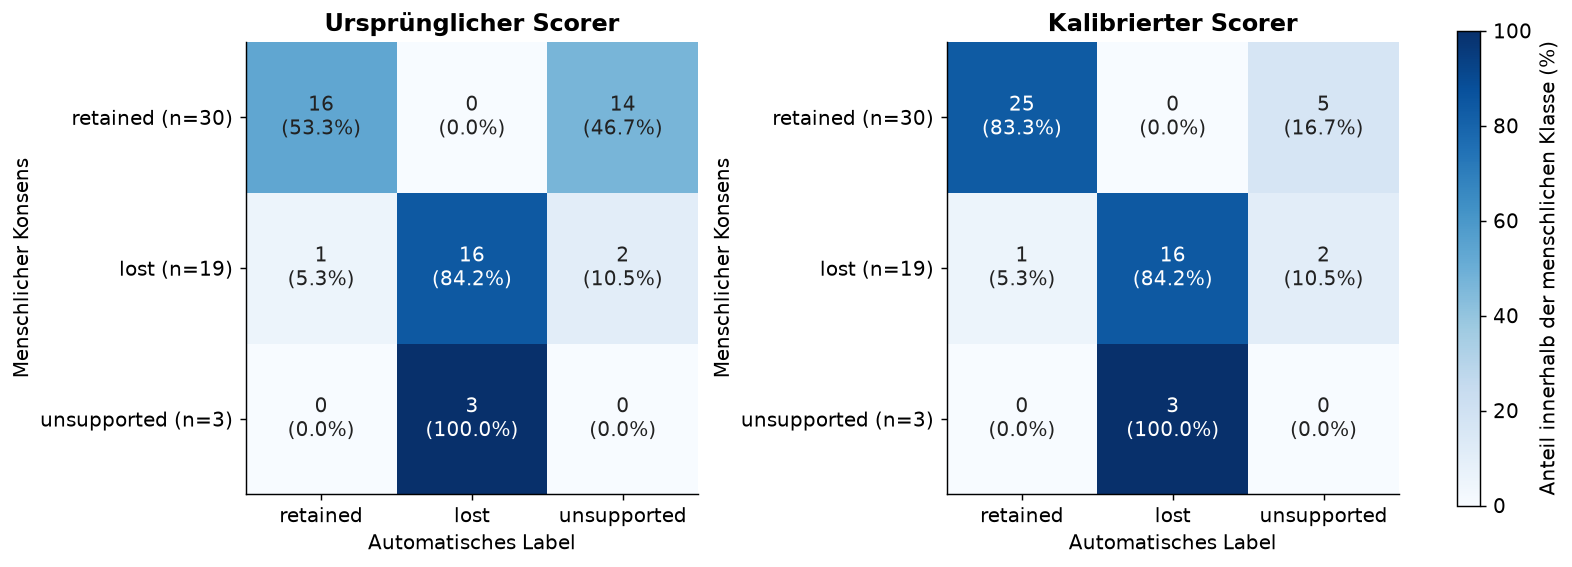

,Scorer,Human-Klasse,Human-Fälle,Precision,Recall,F1
0,Original,retained,30,0.9412,0.5333,0.6809
1,Original,lost,19,0.8421,0.8421,0.8421
2,Original,unsupported,3,0.0000,0.0000,0.0000
3,Kalibriert,retained,30,0.9615,0.8333,0.8929
4,Kalibriert,lost,19,0.8421,0.8421,0.8421
5,Kalibriert,unsupported,3,0.0000,0.0000,0.0000


In [18]:
strict = items[items.strict_eligible].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5.3), layout='constrained')
for ax, column, title in zip(axes, ['model_label', 'calibrated'], ['Ursprünglicher Scorer', 'Kalibrierter Scorer']):
    matrix = confusion_matrix(strict.human_label, strict[column], labels=LABELS)
    shares = matrix / matrix.sum(axis=1, keepdims=True) * 100
    im = ax.imshow(shares, cmap='Blues', vmin=0, vmax=100)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{matrix[i, j]}\n({shares[i, j]:.1f}%)', ha='center', va='center', color='white' if shares[i,
                j] > 55 else '#222222')
    ax.set(xticks=range(3), yticks=range(3), xticklabels=LABELS, yticklabels=[f'{label} (n={matrix[i].sum()})' for i,
        label in enumerate(LABELS)], xlabel='Automatisches Label', ylabel='Menschlicher Konsens', title=title)
    export(pd.DataFrame(matrix, index=LABELS, columns=LABELS).reset_index(names='Human'), f'konfusion_{column}')
fig.colorbar(im, ax=list(axes), shrink=0.7, label='Anteil innerhalb der menschlichen Klasse (%)')
savefig(fig, 'abb_07_qa_kalibrierung')
for column, title in [('model_label', 'Original'), ('calibrated', 'Kalibriert')]:
    group = strict[strict[column].eq('unsupported')]
class_rows = []
for column, title in [('model_label', 'Original'), ('calibrated', 'Kalibriert')]:
    precision, recall, f1, support = precision_recall_fscore_support(strict.human_label, strict[column],
        labels=LABELS, zero_division=0)
    for label, p, r, f, n in zip(LABELS, precision, recall, f1, support):
        class_rows.append({'Scorer': title, 'Human-Klasse': label, 'Human-Fälle': n, 'Precision': p, 'Recall': r, 'F1': f})
class_metrics = pd.DataFrame(class_rows)
display(class_metrics.round(4))
export(class_metrics, 'klassenmetriken')

In [19]:
export(items, 'menschliche_referenz_60_faelle')